# 数学 SFT → QA / 网页：两个交叉检查

本分析回答两个问题：新的 4,096 条 MATH / step-64 模型能否继续区分原来的 A2 与 UltraChat；
同一轮训练的 step-16/32/48 是否已经出现网页反向信号。

这是观察到原 step-64 网页结果后的诊断。只评估已有 checkpoint，没有训练或新增梯度测量，
不以这些评估集选择 checkpoint，保留原 step-64 正式结果。
**loss 下降量与相对下降比例并列考察，不设主次，不翻转分数。**

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score, roc_curve
root = Path.cwd(); snap = root / 'snapshot'
manifest = json.loads((root / 'manifest.json').read_text())
for name, info in manifest['files'].items():
    assert hashlib.sha256((snap / name).read_bytes()).hexdigest() == info['sha256'], name
metrics = json.loads((snap / 'metrics.json').read_text())
qa = pd.read_parquet(snap / 'qa_per_example.parquet')
web = pd.read_parquet(snap / 'web_per_document.parquet')
qa_ids = json.loads((snap / 'qa_length_matched_ids.json').read_text())
web_ids = json.loads((snap / 'web_length_matched_ids.json').read_text())
keys = ['delta_loss', 'relative_gain']
baselines = ['neg_ref_loss', 'neg_sft_loss']
probes = ['legacy_algebra1024_step32', 'math4096_step64']
probe_names = {probes[0]: '原 Algebra 1024 / step 32', probes[1]: '新 MATH 4096 / step 64'}
fresh = qa.loc[qa.probe == probes[1]].copy()
colors = {'A': '#2379B5', 'C': '#DD7C32', 'math': '#2379B5', 'background': '#DD7C32'}
def interval(x): return f'[{x[0]:.4f}, {x[1]:.4f}]'
print('已验证快照 SHA-256：', len(manifest['files']))

已验证快照 SHA-256： 10


## 1. 固定设置与比较边界

QA 使用原来的 A2=512、UltraChat=512，逐条复用 token IDs 和 response mask；仅计算回答平均 NLL。
旧模型是 Algebra 1,024 条 / batch 32 / step 32，新模型是多科目 MATH 4,096 条 / batch 64 / step 64。
两者训练集和训练预算不同，因此比较检验原 QA 信号能否保留，不把变化归因于单一超参数。

网页使用原来的 1,000 篇 OpenWebMath 与 9,000 篇 FineWeb，共 11,688 个窗口。
每篇先累加窗口 NLL 与评分 token 数，再相除。所有 checkpoint 使用相同文档、窗口和掩码。
网页没有聊天模板。背景来源未标注，可能含数学；来源检索结果不能直接当作语义分类或选数训练收益。

原长度匹配 ID 完全保留：QA 每域 126 条，网页 729 / 6,561 条。
95% 区间来自 2,000 次按类分层、按问题/重复文档组 bootstrap，不包含训练随机性。

,checkpoint_step,mean_nll,fraction_improved
0,0,0.74350,0.00000
1,16,0.62777,0.91602
2,32,0.61166,0.94336
3,48,0.59960,0.95898
4,64,0.59402,0.97656


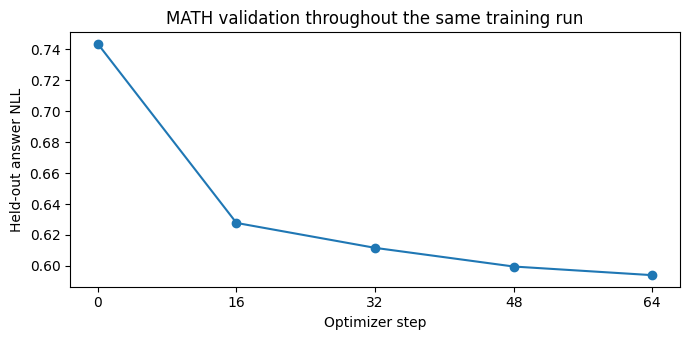

In [2]:
val = pd.DataFrame(metrics['target_validation'])
display(val[['checkpoint_step', 'mean_nll', 'fraction_improved']].round(5))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(val.checkpoint_step, val.mean_nll, 'o-')
ax.set(xlabel='Optimizer step', ylabel='Held-out answer NLL', title='MATH validation throughout the same training run', xticks=val.checkpoint_step)
fig.tight_layout(); plt.show(); plt.close(fig)

## 2. 新模型对原 A2 / UltraChat 的 loss 变化

,probe,domain,examples,fraction_improved,ref_mean_nll,sft_mean_nll,delta_loss,relative_gain
0,原 Algebra 1024 / step 32,A,512,0.97461,0.80926,0.63738,0.17187,0.21629
1,原 Algebra 1024 / step 32,C,512,0.06250,1.09936,1.16540,-0.06605,-0.08393
2,新 MATH 4096 / step 64,A,512,0.99219,0.80926,0.62375,0.18551,0.23350
3,新 MATH 4096 / step 64,C,512,0.06055,1.09936,1.15933,-0.05997,-0.07866


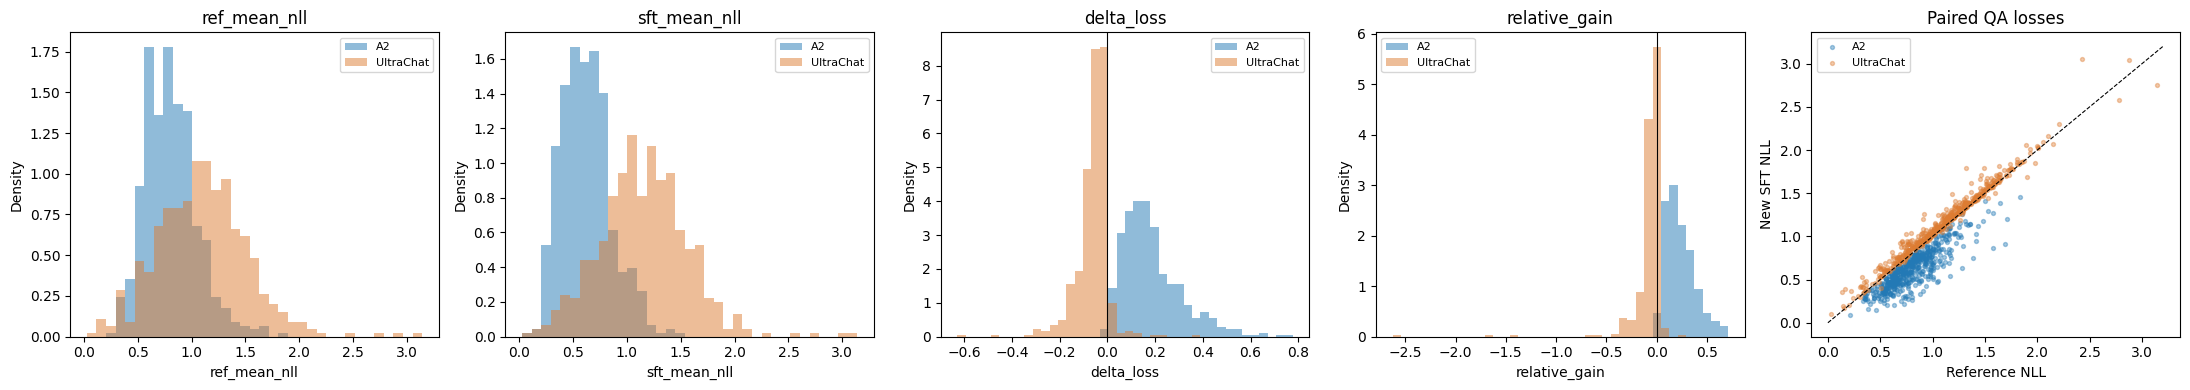

全部样本参与图示和统计，未按分数或内容删除样本。


In [3]:
display(pd.DataFrame([{'probe': probe_names[p], 'domain': d, **v}
    for p, r in metrics['qa']['probes'].items() for d, v in r['summary'].items()]).round(5))
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
columns = ['ref_mean_nll', 'sft_mean_nll', 'delta_loss', 'relative_gain']
shared = np.histogram_bin_edges(fresh[['ref_mean_nll', 'sft_mean_nll']].to_numpy().ravel(), bins=35)
for ax, col in zip(axes, columns):
    bins = shared if col.endswith('mean_nll') else np.histogram_bin_edges(fresh[col], bins=40)
    for domain, group in fresh.groupby('domain'):
        ax.hist(group[col], bins=bins, density=True, alpha=.5, color=colors[domain], label='A2' if domain == 'A' else 'UltraChat')
    ax.set(xlabel=col, ylabel='Density', title=col)
    if col in keys: ax.axvline(0, color='black', linewidth=.8)
for domain, group in fresh.groupby('domain'):
    axes[4].scatter(group.ref_mean_nll, group.sft_mean_nll, s=8, alpha=.4, color=colors[domain], label='A2' if domain == 'A' else 'UltraChat')
upper = fresh[['ref_mean_nll','sft_mean_nll']].to_numpy().max() * 1.02
axes[4].plot([0, upper], [0, upper], 'k--', linewidth=.8)
axes[4].set(xlabel='Reference NLL', ylabel='New SFT NLL', title='Paired QA losses')
for ax in axes: ax.legend(fontsize=8)
fig.tight_layout(); plt.show(); plt.close(fig)
print('全部样本参与图示和统计，未按分数或内容删除样本。')

## 3. QA 区分度是否保留：旧模型与新模型、长度控制和原始 loss 基线

,probe,pool,score,AUC,95% CI,AP
0,原 Algebra 1024 / step 32,main,delta_loss,0.9857,"[0.9782, 0.9921]",0.9830
1,原 Algebra 1024 / step 32,main,relative_gain,0.9869,"[0.9795, 0.9931]",0.9890
2,原 Algebra 1024 / step 32,main,neg_ref_loss,0.7339,"[0.7006, 0.7654]",0.6387
3,原 Algebra 1024 / step 32,main,neg_sft_loss,0.8722,"[0.8496, 0.8932]",0.8186
4,原 Algebra 1024 / step 32,main,pos_ref_loss,0.2661,"[0.2346, 0.2994]",0.3615
5,原 Algebra 1024 / step 32,main,pos_sft_loss,0.1278,"[0.1068, 0.1504]",0.3267
6,原 Algebra 1024 / step 32,length_matched,delta_loss,0.9727,"[0.9526, 0.9896]",0.9706
7,原 Algebra 1024 / step 32,length_matched,relative_gain,0.9722,"[0.9518, 0.9887]",0.9759
8,原 Algebra 1024 / step 32,length_matched,neg_ref_loss,0.7654,"[0.7000, 0.8260]",0.6681
9,原 Algebra 1024 / step 32,length_matched,neg_sft_loss,0.8795,"[0.8330, 0.9233]",0.8453


,pool,score,新模型 AUC − 旧模型 AUC,paired 95% CI
0,main,delta_loss,0.0058,"[0.0021, 0.0104]"
1,main,relative_gain,0.0092,"[0.0043, 0.0151]"
2,length_matched,delta_loss,0.0094,"[-0.0026, 0.0245]"
3,length_matched,relative_gain,0.0201,"[0.0070, 0.0367]"


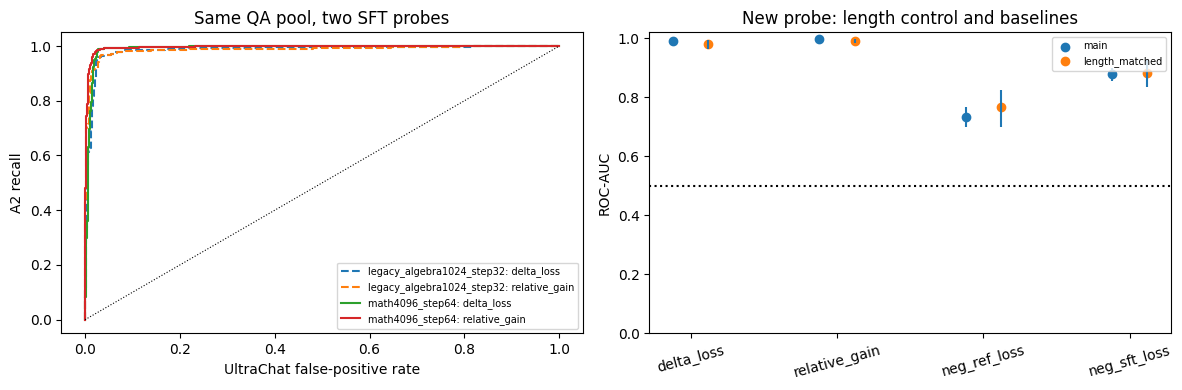

In [4]:
rows = []
for probe in probes:
    for pool in ['main', 'length_matched']:
        for key, value in metrics['qa']['probes'][probe][pool]['scores'].items():
            rows.append({'probe': probe_names[probe], 'pool': pool, 'score': key,
                'AUC': value['roc_auc'], '95% CI': interval(value['roc_auc_ci95']), 'AP': value['average_precision']})
display(pd.DataFrame(rows).round(4))
display(pd.DataFrame([{'pool': pool, 'score': key, '新模型 AUC − 旧模型 AUC': value['auc_difference_after_minus_before'],
    'paired 95% CI': interval(value['ci95'])} for pool, r in metrics['qa']['paired_new_minus_old'].items() for key, value in r.items()]).round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for probe, style in zip(probes, ['--', '-']):
    frame = qa.loc[qa.probe == probe]; y = (frame.domain == 'A').astype(int)
    for key in keys:
        x, t, _ = roc_curve(y, frame[key])
        axes[0].plot(x, t, linestyle=style, label=f'{probe}: {key}')
axes[0].plot([0,1],[0,1],'k:',linewidth=.8)
axes[0].set(xlabel='UltraChat false-positive rate', ylabel='A2 recall', title='Same QA pool, two SFT probes')
for offset, pool in [(-.12, 'main'), (.12, 'length_matched')]:
    scores = metrics['qa']['probes'][probes[1]][pool]['scores']
    for i, key in enumerate(keys + baselines):
        axes[1].vlines(i+offset, *scores[key]['roc_auc_ci95'])
    axes[1].scatter(np.arange(4)+offset, [scores[k]['roc_auc'] for k in keys+baselines], label=pool)
axes[1].axhline(.5, linestyle=':', color='black')
axes[1].set(xticks=np.arange(4), xticklabels=keys+baselines, ylabel='ROC-AUC', ylim=(0,1.02), title='New probe: length control and baselines')
axes[1].tick_params(axis='x', labelrotation=15)
for ax in axes: ax.legend(fontsize=7)
fig.tight_layout(); plt.show(); plt.close(fig)

## 4. 同一轮训练的网页信号：step 16 / 32 / 48 / 64

,step,pool,score,AUC,95% CI,AP,top-10% math-source retrieved,top-10% source precision
0,16,main,delta_loss,0.2866,"[0.2683, 0.3046]",0.0658,37,0.0370
1,16,main,relative_gain,0.2320,"[0.2141, 0.2504]",0.0655,47,0.0470
6,16,length_matched,delta_loss,0.2788,"[0.2568, 0.3012]",0.0679,39,0.0535
7,16,length_matched,relative_gain,0.2321,"[0.2099, 0.2550]",0.0713,50,0.0686
12,32,main,delta_loss,0.2849,"[0.2665, 0.3023]",0.0656,37,0.0370
13,32,main,relative_gain,0.2039,"[0.1870, 0.2210]",0.0622,41,0.0410
18,32,length_matched,delta_loss,0.2731,"[0.2513, 0.2951]",0.0673,40,0.0549
19,32,length_matched,relative_gain,0.2022,"[0.1819, 0.2239]",0.0663,44,0.0604
24,48,main,delta_loss,0.2919,"[0.2736, 0.3096]",0.0665,40,0.0400
25,48,main,relative_gain,0.2088,"[0.1911, 0.2261]",0.0632,44,0.0440


,step,pool,score,AUC,95% CI,AP,top-10% math-source retrieved,top-10% source precision
2,16,main,neg_ref_loss,0.8872,"[0.8745, 0.8999]",0.6402,610,0.610
3,16,main,neg_sft_loss,0.8857,"[0.8731, 0.8984]",0.6349,605,0.605
14,32,main,neg_ref_loss,0.8872,"[0.8745, 0.8999]",0.6402,610,0.610
15,32,main,neg_sft_loss,0.8849,"[0.8721, 0.8977]",0.6332,604,0.604
26,48,main,neg_ref_loss,0.8872,"[0.8745, 0.8999]",0.6402,610,0.610
27,48,main,neg_sft_loss,0.8849,"[0.8722, 0.8976]",0.6332,604,0.604
38,64,main,neg_ref_loss,0.8872,"[0.8745, 0.8999]",0.6402,610,0.610
39,64,main,neg_sft_loss,0.8850,"[0.8723, 0.8978]",0.6336,606,0.606


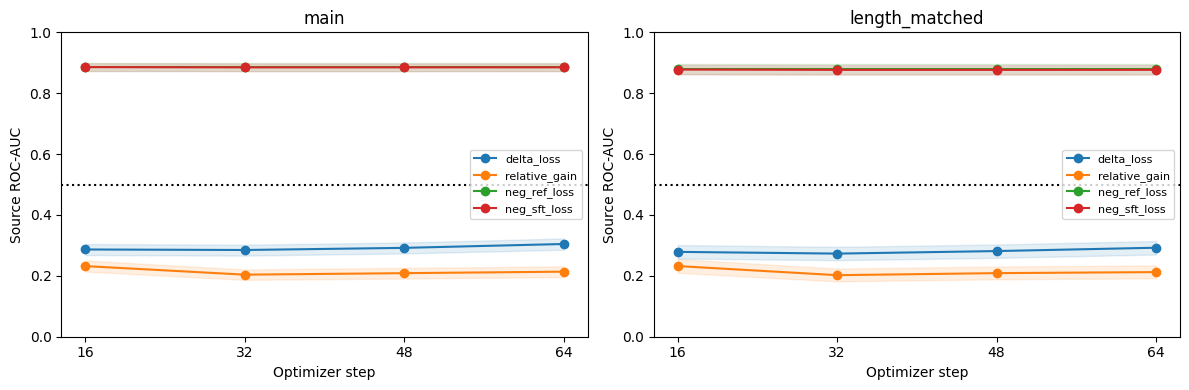

未画 step-0 的差值 AUC：两个模型相同时全部差值为零，AUC 按定义为 0.5。
原始池 top 10% 选择 1,000 篇，随机期望找回 100 篇注入文档；长度匹配池选择 729 篇，随机期望 72.9 篇。


In [5]:
records = []
for step, result in metrics['web'].items():
    for pool in ['main', 'length_matched']:
        for key, value in result[pool]['scores'].items():
            records.append({'step': int(step), 'pool': pool, 'score': key, 'AUC': value['roc_auc'],
                '95% CI': interval(value['roc_auc_ci95']), 'AP': value['average_precision'],
                'top-10% math-source retrieved': value['top']['0.1']['retrieved_math_source'],
                'top-10% source precision': value['top']['0.1']['source_precision']})
table = pd.DataFrame(records)
display(table.loc[table.score.isin(keys)].round(4))
display(table.loc[(table.pool == 'main') & table.score.isin(baselines)].round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
steps = sorted(web.checkpoint_step.unique())
for ax, pool in zip(axes, ['main', 'length_matched']):
    for key in keys + baselines:
        values = [metrics['web'][str(s)][pool]['scores'][key] for s in steps]
        line, = ax.plot(steps, [v['roc_auc'] for v in values], 'o-', label=key)
        ax.fill_between(steps, [v['roc_auc_ci95'][0] for v in values], [v['roc_auc_ci95'][1] for v in values], color=line.get_color(), alpha=.12)
    ax.axhline(.5, color='black', linestyle=':')
    ax.set(xlabel='Optimizer step', ylabel='Source ROC-AUC', title=pool, xticks=steps, ylim=(0,1))
    ax.legend(fontsize=8)
fig.tight_layout(); plt.show(); plt.close(fig)
print('未画 step-0 的差值 AUC：两个模型相同时全部差值为零，AUC 按定义为 0.5。')
print('原始池 top 10% 选择 1,000 篇，随机期望找回 100 篇注入文档；长度匹配池选择 729 篇，随机期望 72.9 篇。')

## 5. 哪类网页的 loss 在变化？

,step,source,fraction_improved,ref_mean_nll,sft_mean_nll,delta_loss,relative_gain
0,16,background,0.286111,2.733867,2.738543,-0.004677,-0.002011
1,16,math,0.099000,1.705336,1.728197,-0.022861,-0.022069
2,32,background,0.175111,2.733867,2.744413,-0.010546,-0.004198
3,32,math,0.059000,1.705336,1.737503,-0.032167,-0.030226
4,48,background,0.168222,2.733867,2.745038,-0.011171,-0.004433
5,48,math,0.060000,1.705336,1.737888,-0.032552,-0.030857
6,64,background,0.155333,2.733867,2.746040,-0.012174,-0.004794
7,64,math,0.056000,1.705336,1.737664,-0.032328,-0.030362


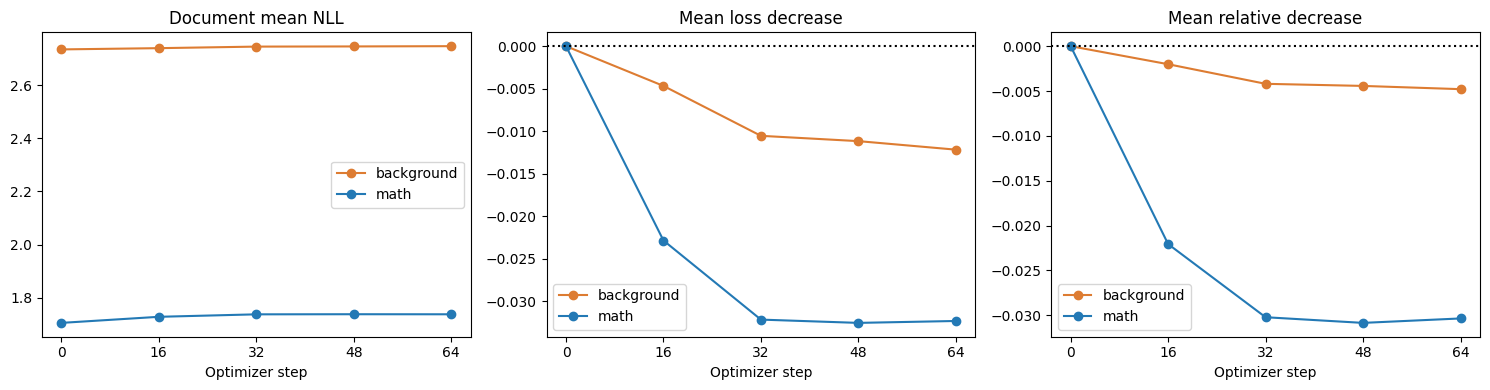

,earlier_step,score,AUC64 − AUCearlier,paired 95% CI
0,16,delta_loss,0.0180,"[0.0093, 0.0269]"
1,16,relative_gain,-0.0183,"[-0.0272, -0.0093]"
2,32,delta_loss,0.0197,"[0.0151, 0.0246]"
3,32,relative_gain,0.0098,"[0.0051, 0.0147]"
4,48,delta_loss,0.0127,"[0.0105, 0.0149]"
5,48,relative_gain,0.0049,"[0.0025, 0.0073]"


In [6]:
summaries = pd.DataFrame([{'step': int(step), 'source': source, 'fraction_improved': v['positive_delta_fraction'],
    **{key: v[key]['mean'] for key in ['ref_mean_nll','sft_mean_nll','delta_loss','relative_gain']}}
    for step, result in metrics['web'].items() for source, v in result['document_summary'].items()])
display(summaries.round(6))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for source, group in summaries.groupby('source'):
    group = group.sort_values('step')
    axes[0].plot([0]+group.step.tolist(), [group.ref_mean_nll.iloc[0]]+group.sft_mean_nll.tolist(), 'o-', label=source, color=colors[source])
    for ax, key in zip(axes[1:], keys):
        ax.plot([0]+group.step.tolist(), [0]+group[key].tolist(), 'o-', label=source, color=colors[source])
for ax, title in zip(axes, ['Document mean NLL', 'Mean loss decrease', 'Mean relative decrease']):
    ax.set(xlabel='Optimizer step', title=title, xticks=[0,16,32,48,64]); ax.legend()
for ax in axes[1:]: ax.axhline(0, color='black', linestyle=':')
fig.tight_layout(); plt.show(); plt.close(fig)
display(pd.DataFrame([{'earlier_step': int(step), 'score': key,
    'AUC64 − AUCearlier': v['auc_difference_after_minus_before'], 'paired 95% CI': interval(v['ci95'])}
    for step, r in metrics['web_paired_auc_final_minus_intermediate'].items() for key,v in r.items()]).round(4))

## 6. 结果复核与解释边界

In [7]:
for probe in probes:
    frame = qa.loc[qa.probe == probe]
    assert len(frame) == 1024 and frame.id.is_unique
    for pool, subset in [('main', frame), ('length_matched', frame.loc[frame.id.isin(qa_ids)])]:
        for key in keys+baselines:
            np.testing.assert_allclose(roc_auc_score((subset.domain == 'A').astype(int), subset[key]),
                metrics['qa']['probes'][probe][pool]['scores'][key]['roc_auc'], atol=1e-12, rtol=0)
for step, frame in web.groupby('checkpoint_step'):
    assert len(frame) == 10000 and frame.id.is_unique and frame.injected_math_source.sum() == 1000
    assert frame.scored_tokens.sum() == 9188836 and frame.windows.sum() == 11688
    for pool, subset in [('main', frame), ('length_matched', frame.loc[frame.id.isin(web_ids)])]:
        for key in keys+baselines:
            np.testing.assert_allclose(roc_auc_score(subset.injected_math_source.astype(int), subset[key]),
                metrics['web'][str(step)][pool]['scores'][key]['roc_auc'], atol=1e-12, rtol=0)
print('QA reference 与旧结果最大 NLL 差：', metrics['qa']['reference_max_nll_difference'])
print('与新训练集的规范化问题重合：', metrics['qa']['overlap']['normalized_question_overlap_ids'])
print('旧 notebook 保持原样：', metrics['original_notebooks_unchanged'])
for key in keys:
    q = metrics['qa']['probes'][probes[1]]['main']['scores'][key]
    w = [metrics['web'][str(s)]['main']['scores'][key]['roc_auc'] for s in [16,32,48,64]]
    display(Markdown(f"**{key}**：新模型 QA AUC **{q['roc_auc']:.4f}**（95% CI {interval(q['roc_auc_ci95'])}）；网页 step 16/32/48/64 AUC 依次为 **" + ' / '.join(f'{v:.4f}' for v in w) + '**。'))
qa_preserved = all(metrics['qa']['probes'][probes[1]]['main']['scores'][k]['roc_auc_ci95'][0] > .5 for k in keys)
early_inverted = all(metrics['web']['16']['main']['scores'][k]['roc_auc_ci95'][1] < .5 for k in keys)
if qa_preserved and early_inverted:
    display(Markdown('**本轮观测：新模型保留了原 QA 区分信号，而网页反向信号在 step 16 已出现。** '
        '这支持 QA 与网页任务之间的迁移限制，并削弱“只有后期训练过度才造成网页失效”的解释。'))

QA reference 与旧结果最大 NLL 差： 1.0371208190917969e-05
与新训练集的规范化问题重合： []
旧 notebook 保持原样： True


**delta_loss**：新模型 QA AUC **0.9915**（95% CI [0.9854, 0.9965]）；网页 step 16/32/48/64 AUC 依次为 **0.2866 / 0.2849 / 0.2919 / 0.3046**。

**relative_gain**：新模型 QA AUC **0.9960**（95% CI [0.9928, 0.9984]）；网页 step 16/32/48/64 AUC 依次为 **0.2320 / 0.2039 / 0.2088 / 0.2137**。

**本轮观测：新模型保留了原 QA 区分信号，而网页反向信号在 step 16 已出现。** 这支持 QA 与网页任务之间的迁移限制，并削弱“只有后期训练过度才造成网页失效”的解释。

最早观测是 step 16，不能推断 step 1–15 的情况。
这两个检查仍无法单独区分聊天格式、答案/全文预测目标、题型及网页来源差异的因果贡献。
step 64 的正式结果保持不变，没有从诊断中重新挑选最优 checkpoint。